In [13]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import os, psutil
import numpy as np
import sys
import subprocess

# Matplotlib imports
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import AutoLocator, MaxNLocator, AutoMinorLocator

# Scipy imports
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator

# Iris imports
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
import simplekml

system_path_base = "/Users/amritrajdash/programming/TEAMx/amrit_exploration"

from pathlib import Path
sys.path.append(f"{system_path_base}")

import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = f"{system_path_base}/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
#original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = f"{system_path_base}/momentum_fluxes/wEOP_sonde_data_sterzing/" 

raw_sonde_list = sorted(Path(f"{data_path_base}").glob("*.nc"))
index = 3

# %%
# Paths for the sonde and model data

sonde_id = raw_sonde_list[index].stem[13:21]

raw_data_path = raw_sonde_list[index]

data_path_orog = "orography_u-eb392_run1_0p3km.nc"

#original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

mem = psutil.Process(os.getpid()).memory_info().rss / 1024**3
print(f"Current RAM usage: {mem:.2f} GB")

sonde_id

len(raw_sonde_list)

Current RAM usage: 0.12 GB


148

In [2]:
# %%
# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_r_path = f"{raw_data_path}"

#cubelist_mo_path = f"{original_model_data_path}"
#orog_cube_path = f"{data_path_base}/{data_path_orog}"

#cubelist_mo = iris.load(cubelist_mo_path)
#orog_cube = iris.load(orog_cube_path)

cubelist_r = iris.load(cubelist_r_path)


In [3]:
alts_list = []
lats_list = []
lons_list = []

sonde_title_labels = []


for i in range(0, len(raw_sonde_list)):
    try:
        alt_raw, alt_mask = tx.nonans_cubedata(raw_sonde_list[i], "altitude")
        alt_raw[np.where(np.abs(alt_raw) > 1e5)] = np.nan
        alt_nonans, nan_mask_alt = tx.fill_nans(alt_raw)
        
        lat_raw, lat_mask = tx.nonans_cubedata(raw_sonde_list[i], "latitude")
        lat_raw[np.where(np.abs(lat_raw) > 1e5)] = np.nan
        lat_nonans, nan_mask_lat = tx.fill_nans(lat_raw)

        lon_raw, lon_mask = tx.nonans_cubedata(raw_sonde_list[i], "longitude")
        lon_raw[np.where(np.abs(lon_raw) > 1e5)] = np.nan
        lon_nonans, nan_mask_lon = tx.fill_nans(lon_raw)

        name = raw_sonde_list[i].stem
        id = name[13:21]
        sonde_title_labels.append(id)

        alts_list.append(1e-3*alt_nonans)
        lats_list.append(lat_nonans)
        lons_list.append(lon_nonans)


    except ValueError:
        continue
        


In [4]:
# This is the minimum number of samples from all the sondes in the lists above
# All other sondes will get sampled accordingly
median_len = int(np.nanmax([len(i) for i in alts_list]))
max_alt_idx = np.argmax([np.nanmax(i) for i in alts_list])

indices_list = []
for i in alts_list:
    indices_list.append(np.linspace(0, len(i)-1 , median_len, dtype=int))

sampled_alts_list = []
sampled_lats_list = []
sampled_lons_list = []

for i,j in enumerate(alts_list):  
    sampled_alts_list.append(alts_list[i][indices_list[i]])
    sampled_lats_list.append(lats_list[i][indices_list[i]])
    sampled_lons_list.append(lons_list[i][indices_list[i]])





(10.5, 13.0)

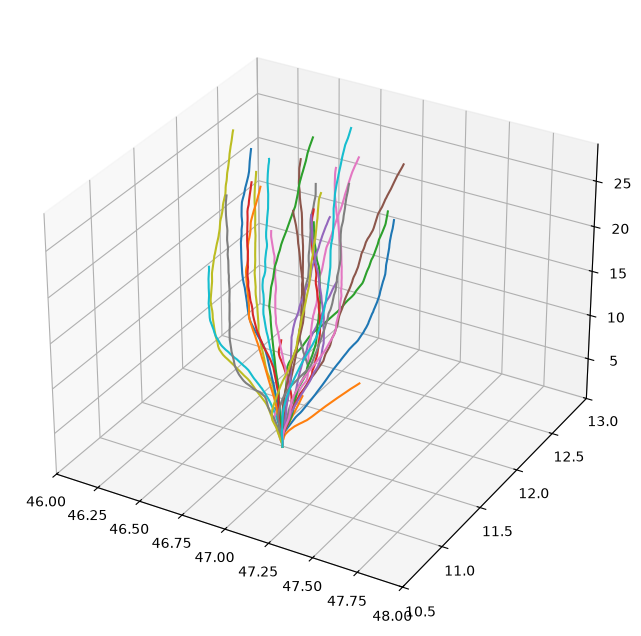

In [10]:
# Now overlay the trajectories onto a flat map

fig = plt.figure(figsize=(10, 8))
ax = fig.subplots(1, 1, subplot_kw={"projection":"3d"})

for i in range(0, len(sampled_lons_list), 5):
    ax.plot(sampled_lats_list[i], sampled_lons_list[i], sampled_alts_list[i])

ax.set_xlim(46, 48)
ax.set_ylim(10.5, 13)

In [12]:
kml = simplekml.Kml()

for i in range(0, len(sampled_lats_list), 5):

    lats = np.asarray(sampled_lats_list[i])
    lons = np.asarray(sampled_lons_list[i])
    alts = np.asarray(sampled_alts_list[i]) * 1000  # km -> m

    line = kml.newlinestring(name=f"Sonde {i}")
    line.coords = list(zip(lons, lats, alts))
    
    line.style.linestyle.color = simplekml.Color.rgb(0, 255, 255)
    line.style.linestyle.width = 3
    line.altitudemode = simplekml.AltitudeMode.absolute

kml.save("sonde_trajectories.kml")